# Ablation Comparison (cross_day & cross_subject)

对比 4 组实验的 `cross_day` 和 `cross_subject` 结果（mean±sd，5 seeds）：
- **CNN-Full** — `result_day_td/`
- **CNN-Ablation** — `result_day_td_ablation/`
- **MLP-Full** — `results_mlp/`
- **MLP-Ablation** — `results_mlp_ablation/`

In [1]:
import os, re, glob
import numpy as np
import pandas as pd

EXPERIMENTS = {
    'CNN-Full':     '/root/zjm/cadt/result_day_td',
    'CNN-Ablation': '/root/zjm/cadt/result_day_td_ablation',
    'MLP-Full':     '/root/zjm/cadt/results_mlp',
    'MLP-Ablation': '/root/zjm/cadt/results_mlp_ablation',
}
SPLIT_MODES = ['cross_day', 'cross_subject']

OVERALL_METRICS = [
    ('Test MSE',              'Test MSE'),
    ('Test MAE',              'Test MAE'),
    ('Test RMSE',             'Test RMSE'),
    ('Test R2',               'Test R2'),
    ('Test Avg R2 (per-dim)', 'Test Avg R2'),
    ('Test Pearson',          'Test Pearson'),
    ('Test Spearman',         'Test Spearman'),
    ('Val MSE',               'Val MSE'),
    ('Val MAE',               'Val MAE'),
    ('Val RMSE',              'Val RMSE'),
    ('Val R2',                'Val R2'),
    ('Val Avg R2 (per-dim)',  'Val Avg R2'),
    ('Val Pearson',           'Val Pearson'),
    ('Val Spearman',          'Val Spearman'),
]

EMOTIONS = [
    'inspired', 'alert', 'determined', 'attentive', 'active',
    'hostile', 'nervous', 'upset', 'afraid', 'ashamed', 'fatigue'
]
PER_EMOTION_METRICS = ['MSE', 'MAE', 'R2', 'Pearson', 'Spearman']

print('Config loaded.')

Config loaded.


## 解析函数

In [2]:
def parse_results_txt(filepath):
    with open(filepath, 'r') as f:
        text = f.read()

    overall = {}
    for key in [m[0] for m in OVERALL_METRICS]:
        pattern = re.escape(key) + r":\s*([-+]?\d*\.?\d+)"
        m = re.search(pattern, text)
        if m:
            overall[key] = float(m.group(1))

    per_emotion_test, per_emotion_val = {}, {}

    test_section = re.search(
        r"--- Per-Emotion Metrics \(Test Set\) ---\s*\n.*?\n-+\n(.*?)(?:\n---|\Z)", text, re.DOTALL
    )
    if test_section:
        for emo in EMOTIONS:
            pattern = rf"^{emo}\s+([\d.]+)\s+([\d.]+)\s+([-+\d.]+)\s+([-+\d.]+)\s+([-+\d.]+)"
            m = re.search(pattern, test_section.group(1), re.MULTILINE)
            if m:
                per_emotion_test[emo] = {
                    'MSE': float(m.group(1)), 'MAE': float(m.group(2)),
                    'R2': float(m.group(3)), 'Pearson': float(m.group(4)), 'Spearman': float(m.group(5)),
                }

    val_section = re.search(
        r"--- Per-Emotion Metrics \(Validation Set\) ---\s*\n.*?\n-+\n(.*?)(?:\n---|\Z)", text, re.DOTALL
    )
    if val_section:
        for emo in EMOTIONS:
            pattern = rf"^{emo}\s+([\d.]+)\s+([\d.]+)\s+([-+\d.]+)\s+([-+\d.]+)\s+([-+\d.]+)"
            m = re.search(pattern, val_section.group(1), re.MULTILINE)
            if m:
                per_emotion_val[emo] = {
                    'MSE': float(m.group(1)), 'MAE': float(m.group(2)),
                    'R2': float(m.group(3)), 'Pearson': float(m.group(4)), 'Spearman': float(m.group(5)),
                }

    return overall, per_emotion_test, per_emotion_val


def collect_experiment(base_dir, split_mode):
    pattern = os.path.join(base_dir, f'*{split_mode}*')
    exp_dirs = sorted(glob.glob(pattern))
    results = []
    for d in exp_dirs:
        rfile = os.path.join(d, 'results.txt')
        if not os.path.exists(rfile):
            continue
        overall, pe_test, pe_val = parse_results_txt(rfile)
        results.append({'dir': os.path.basename(d), 'overall': overall,
                        'per_emotion_test': pe_test, 'per_emotion_val': pe_val})
    return results


def agg_values(all_data, exp_name, key, per_emotion=None, metric=None):
    values = []
    for r in all_data[exp_name]:
        if per_emotion is None:
            if key in r['overall']:
                values.append(r['overall'][key])
        else:
            pe = r['per_emotion_test']
            if per_emotion in pe and metric in pe[per_emotion]:
                values.append(pe[per_emotion][metric])
    return values


def fmt_ms(values):
    if len(values) == 0:
        return 'N/A'
    return f'{np.mean(values):.4f}±{np.std(values, ddof=0):.4f}'

print('Functions ready.')

Functions ready.


## 收集数据

In [3]:
all_data_by_split = {}
for split_mode in SPLIT_MODES:
    all_data_by_split[split_mode] = {}
    for exp_name, exp_dir in EXPERIMENTS.items():
        results = collect_experiment(exp_dir, split_mode)
        all_data_by_split[split_mode][exp_name] = results
        print(f'[{split_mode}] {exp_name}: {len(results)} runs')

[cross_day] CNN-Full: 5 runs
[cross_day] CNN-Ablation: 5 runs
[cross_day] MLP-Full: 5 runs
[cross_day] MLP-Ablation: 5 runs
[cross_subject] CNN-Full: 5 runs
[cross_subject] CNN-Ablation: 5 runs
[cross_subject] MLP-Full: 5 runs
[cross_subject] MLP-Ablation: 5 runs


---
# cross_day

## 1. 总体指标对比

In [4]:
split_mode = 'cross_day'
all_data = all_data_by_split[split_mode]

rows = []
for metric_key, display_name in OVERALL_METRICS:
    row = {'Metric': display_name}
    for exp_name in EXPERIMENTS:
        vals = agg_values(all_data, exp_name, metric_key)
        row[exp_name] = fmt_ms(vals)
    rows.append(row)

df_overall = pd.DataFrame(rows)
df_overall.style.set_caption(f'Overall Metrics — {split_mode} (mean±sd)').set_table_styles([
    {'selector': 'caption', 'props': [('font-size', '16px'), ('font-weight', 'bold')]},
    {'selector': 'th', 'props': [('text-align', 'center')]},
    {'selector': 'td', 'props': [('text-align', 'center')]},
])

,Metric,CNN-Full,CNN-Ablation,MLP-Full,MLP-Ablation
0,Test MSE,0.8413±0.0014,0.8852±0.0325,0.8442±0.0016,0.8843±0.0022
1,Test MAE,0.7230±0.0013,0.7273±0.0173,0.7247±0.0013,0.7256±0.0038
2,Test RMSE,0.9172±0.0008,0.9407±0.0171,0.9188±0.0008,0.9404±0.0012
3,Test R2,0.1779±0.0014,0.1350±0.0317,0.1751±0.0015,0.1358±0.0021
4,Test Avg R2,-0.0135±0.0019,-0.0577±0.0358,-0.0173±0.0023,-0.0700±0.0025
5,Test Pearson,0.0848±0.0776,0.1577±0.0161,0.0282±0.0128,0.1161±0.0119
6,Test Spearman,0.0903±0.0555,0.1838±0.0171,0.0280±0.0113,0.1183±0.0105
7,Val MSE,0.7307±0.0015,0.7977±0.0154,0.7335±0.0006,0.7997±0.0032
8,Val MAE,0.6708±0.0014,0.6902±0.0117,0.6736±0.0014,0.6934±0.0022
9,Val RMSE,0.8548±0.0009,0.8931±0.0086,0.8564±0.0004,0.8943±0.0018


## 2. Per-Emotion Test 指标对比

In [5]:
overall_key_map = {
    'MSE': 'Test MSE', 'MAE': 'Test MAE', 'R2': 'Test R2',
    'Pearson': 'Test Pearson', 'Spearman': 'Test Spearman',
}

for metric in PER_EMOTION_METRICS:
    rows = []
    for emo in EMOTIONS + ['Average']:
        row = {'Emotion': emo}
        for exp_name in EXPERIMENTS:
            if emo == 'Average':
                vals = agg_values(all_data, exp_name, overall_key_map[metric])
            else:
                vals = agg_values(all_data, exp_name, None, per_emotion=emo, metric=metric)
            row[exp_name] = fmt_ms(vals)
        rows.append(row)

    df_emo = pd.DataFrame(rows).set_index('Emotion')
    display(df_emo.style
            .set_caption(f'Per-Emotion Test {metric} — {split_mode} (mean±sd)')
            .set_table_styles([
                {'selector': 'caption', 'props': [('font-size', '14px'), ('font-weight', 'bold')]},
                {'selector': 'th', 'props': [('text-align', 'center')]},
                {'selector': 'td', 'props': [('text-align', 'center')]},
            ])
            .set_properties(**{'background-color': '#f9f9f9'}, subset=pd.IndexSlice['Average', :]))

,CNN-Full,CNN-Ablation,MLP-Full,MLP-Ablation
Emotion,,,,
inspired,0.8095±0.0013,0.8871±0.0591,0.8115±0.0031,0.8681±0.0257
alert,0.5828±0.0011,0.5899±0.0261,0.5831±0.0003,0.6141±0.0138
determined,1.0272±0.0040,1.1256±0.0348,1.0310±0.0028,1.0839±0.0127
attentive,1.3496±0.0017,1.4749±0.1203,1.3426±0.0014,1.3654±0.0170
active,1.0636±0.0015,1.1741±0.0659,1.0640±0.0021,1.1672±0.0299
hostile,0.5154±0.0020,0.5365±0.0218,0.5166±0.0041,0.5551±0.0083
nervous,0.8057±0.0013,0.8211±0.1114,0.8091±0.0017,0.8303±0.0163
upset,1.0215±0.0046,1.0524±0.1166,1.0309±0.0086,1.0661±0.0080
afraid,0.7144±0.0051,0.6982±0.0516,0.7215±0.0044,0.7318±0.0127


,CNN-Full,CNN-Ablation,MLP-Full,MLP-Ablation
Emotion,,,,
inspired,0.7037±0.0008,0.7728±0.0317,0.7068±0.0040,0.7676±0.0111
alert,0.6680±0.0021,0.6241±0.0298,0.6672±0.0017,0.6437±0.0034
determined,0.7972±0.0052,0.8498±0.0257,0.8013±0.0038,0.8377±0.0051
attentive,0.9375±0.0037,0.9976±0.0318,0.9439±0.0022,0.9636±0.0075
active,0.8767±0.0013,0.9017±0.0198,0.8772±0.0024,0.8844±0.0109
hostile,0.5366±0.0048,0.4892±0.0355,0.5328±0.0077,0.4989±0.0084
nervous,0.7500±0.0015,0.7059±0.0174,0.7505±0.0004,0.7232±0.0054
upset,0.8172±0.0030,0.8137±0.0247,0.8224±0.0038,0.8190±0.0106
afraid,0.6588±0.0033,0.6241±0.0318,0.6544±0.0036,0.6214±0.0070


,CNN-Full,CNN-Ablation,MLP-Full,MLP-Ablation
Emotion,,,,
inspired,-0.0076±0.0016,-0.1042±0.0735,-0.0101±0.0039,-0.0806±0.0320
alert,0.0010±0.0019,-0.0112±0.0448,0.0004±0.0005,-0.0527±0.0237
determined,-0.0042±0.0040,-0.1003±0.0340,-0.0078±0.0027,-0.0596±0.0123
attentive,-0.0114±0.0012,-0.1053±0.0901,-0.0061±0.0011,-0.0232±0.0127
active,-0.0023±0.0014,-0.1065±0.0621,-0.0027±0.0020,-0.0999±0.0281
hostile,-0.0103±0.0040,-0.0516±0.0428,-0.0126±0.0080,-0.0882±0.0163
nervous,-0.0195±0.0017,-0.0390±0.1409,-0.0237±0.0022,-0.0505±0.0206
upset,-0.0091±0.0046,-0.0396±0.1152,-0.0184±0.0085,-0.0532±0.0079
afraid,-0.0233±0.0074,-0.0001±0.0739,-0.0334±0.0062,-0.0482±0.0181


,CNN-Full,CNN-Ablation,MLP-Full,MLP-Ablation
Emotion,,,,
inspired,0.0383±0.0592,0.1013±0.0191,-0.0153±0.0887,0.1125±0.0232
alert,0.0992±0.0916,0.1853±0.0532,0.0603±0.0518,0.1196±0.0234
determined,0.0692±0.0923,0.1132±0.0105,0.0264±0.0668,0.1218±0.0150
attentive,0.0768±0.0888,0.1010±0.0428,0.0324±0.0360,0.1706±0.0352
active,-0.0644±0.0551,0.0253±0.0525,-0.0474±0.0280,0.0977±0.0157
hostile,0.0607±0.0530,0.1455±0.0341,0.0867±0.0474,0.0771±0.0342
nervous,0.1718±0.1676,0.2136±0.0980,0.0442±0.0597,0.1099±0.0087
upset,0.1001±0.0907,0.2051±0.0608,0.0425±0.0358,0.1276±0.0158
afraid,0.1339±0.1221,0.2455±0.0570,0.0298±0.0587,0.1426±0.0150


,CNN-Full,CNN-Ablation,MLP-Full,MLP-Ablation
Emotion,,,,
inspired,0.0301±0.0594,0.1327±0.0137,-0.0287±0.0909,0.1082±0.0232
alert,0.1133±0.0673,0.2289±0.0398,0.0454±0.0637,0.1119±0.0219
determined,0.0660±0.0629,0.1514±0.0133,0.0172±0.0651,0.1336±0.0169
attentive,0.0627±0.0761,0.1180±0.0472,0.0376±0.0304,0.1556±0.0254
active,-0.0577±0.0840,0.0386±0.0428,-0.0519±0.0296,0.0938±0.0162
hostile,0.0932±0.0449,0.2077±0.0468,0.0949±0.0453,0.0964±0.0337
nervous,0.1977±0.1552,0.2600±0.1165,0.0515±0.0545,0.1150±0.0099
upset,0.1060±0.0586,0.2199±0.0531,0.0509±0.0377,0.1354±0.0203
afraid,0.1557±0.1084,0.2467±0.0576,0.0298±0.0443,0.1413±0.0189


## 3. 可视化对比

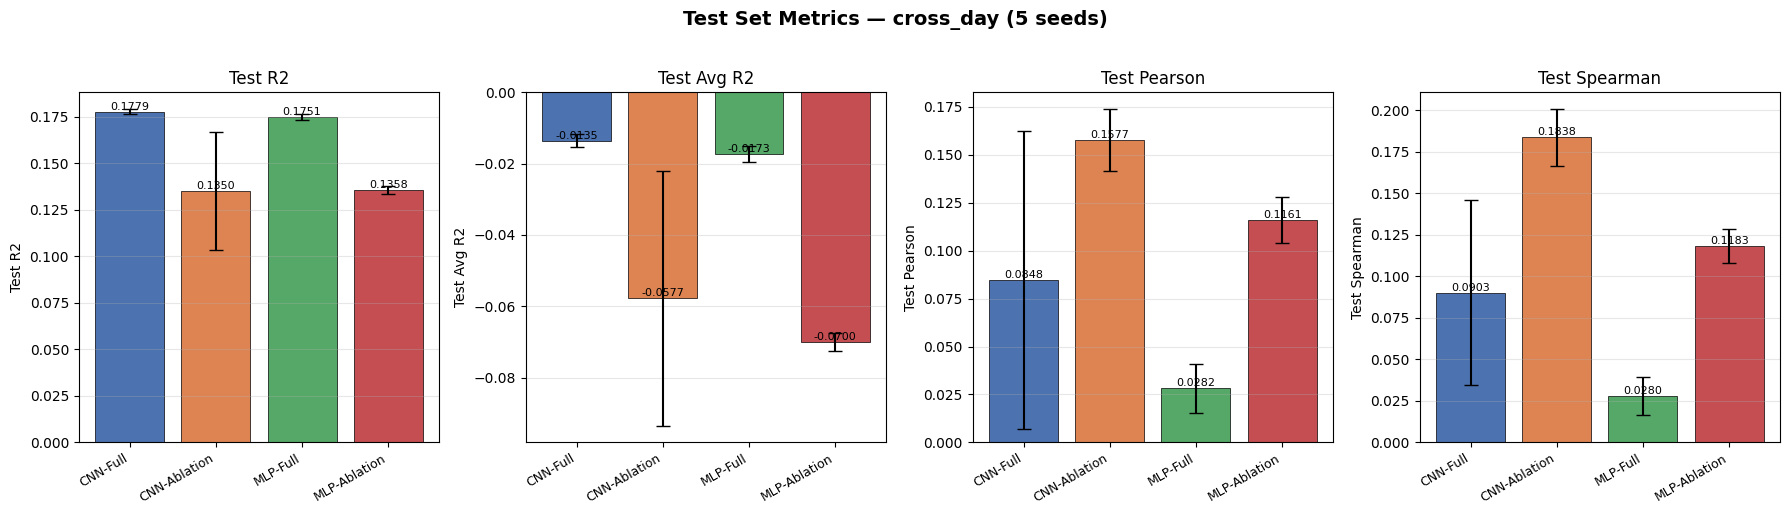

Saved: /root/zjm/cadt_test_code/ablation_comparison_bar_cross_day.png


In [6]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'DejaVu Sans'

exp_names = list(EXPERIMENTS.keys())
colors = ['#4C72B0', '#DD8452', '#55A868', '#C44E52']

plot_metrics = ['Test R2', 'Test Avg R2 (per-dim)', 'Test Pearson', 'Test Spearman']
plot_labels = ['Test R2', 'Test Avg R2', 'Test Pearson', 'Test Spearman']

fig, axes = plt.subplots(1, 4, figsize=(18, 5))

for ax, metric_key, label in zip(axes, plot_metrics, plot_labels):
    means, stds = [], []
    for exp_name in exp_names:
        vals = agg_values(all_data, exp_name, metric_key)
        means.append(np.mean(vals))
        stds.append(np.std(vals, ddof=0))

    bars = ax.bar(range(len(exp_names)), means, yerr=stds, capsize=5,
                  color=colors, edgecolor='black', linewidth=0.5)
    ax.set_xticks(range(len(exp_names)))
    ax.set_xticklabels(exp_names, rotation=30, ha='right', fontsize=9)
    ax.set_ylabel(label)
    ax.set_title(label, fontsize=12)
    ax.axhline(y=0, color='gray', linestyle='--', linewidth=0.5)
    ax.grid(axis='y', alpha=0.3)
    for bar, m in zip(bars, means):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height(),
                f'{m:.4f}', ha='center', va='bottom', fontsize=8)

plt.suptitle(f'Test Set Metrics — {split_mode} (5 seeds)',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(f'/root/zjm/cadt_test_code/ablation_comparison_bar_{split_mode}.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved: /root/zjm/cadt_test_code/ablation_comparison_bar_{split_mode}.png')

## 4. Per-Emotion Pearson 雷达图

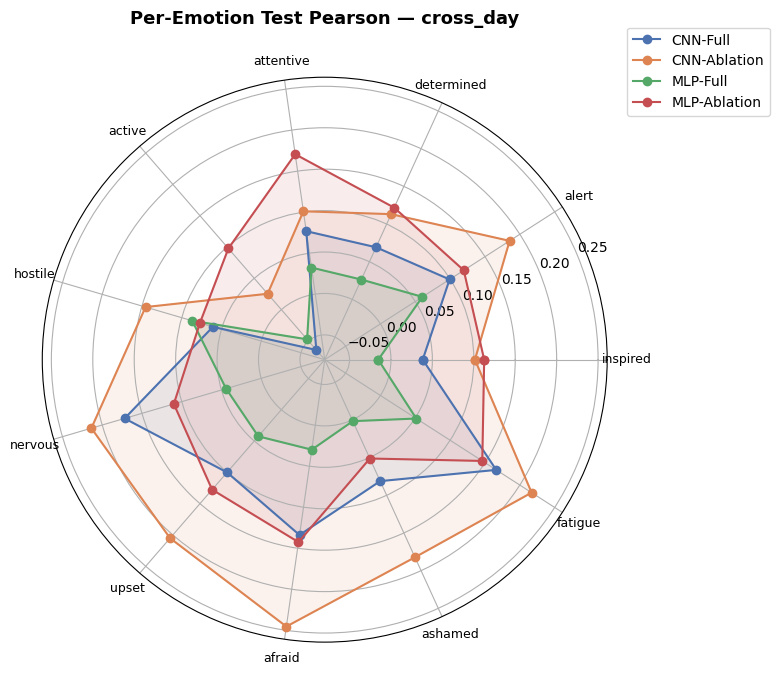

Saved: /root/zjm/cadt_test_code/ablation_radar_pearson_cross_day.png


In [7]:
fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))

angles = np.linspace(0, 2 * np.pi, len(EMOTIONS), endpoint=False).tolist()
angles += angles[:1]

for exp_name, color in zip(exp_names, colors):
    means = []
    for emo in EMOTIONS:
        vals = agg_values(all_data, exp_name, None, per_emotion=emo, metric='Pearson')
        means.append(np.mean(vals))
    means += means[:1]
    ax.plot(angles, means, 'o-', linewidth=1.5, label=exp_name, color=color)
    ax.fill(angles, means, alpha=0.1, color=color)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(EMOTIONS, fontsize=9)
ax.set_title(f'Per-Emotion Test Pearson — {split_mode}', fontsize=13, fontweight='bold', y=1.08)
ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))
ax.grid(True)
plt.tight_layout()
plt.savefig(f'/root/zjm/cadt_test_code/ablation_radar_pearson_{split_mode}.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved: /root/zjm/cadt_test_code/ablation_radar_pearson_{split_mode}.png')

### Per-Emotion \u5206\u7ec4\u67f1\u72b6\u56fe (Pearson / Spearman / R2)\n
\u6bcf\u4e2a\u60c5\u7eea\u5c55\u793a 4 \u7ec4\u5b9e\u9a8c\u7684 mean\u00b1sd\uff085 seeds\uff09

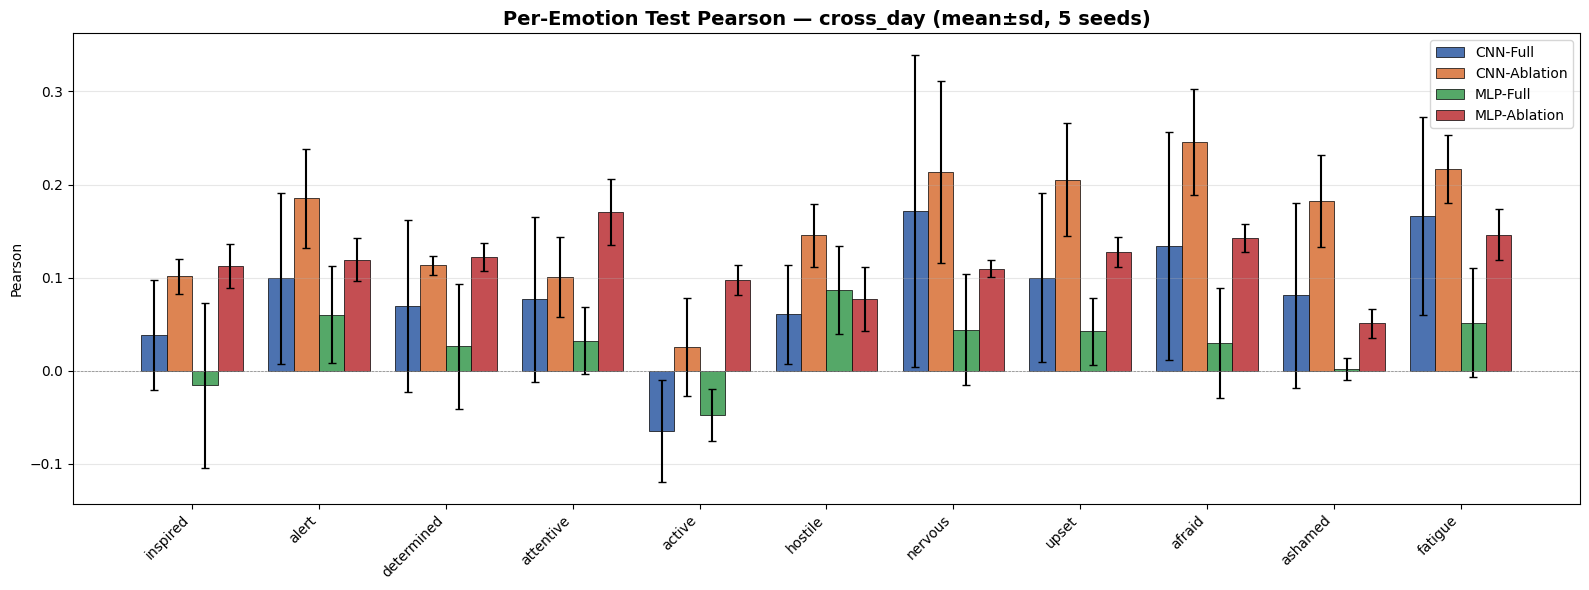

Saved: per_emotion_pearson_cross_day.png


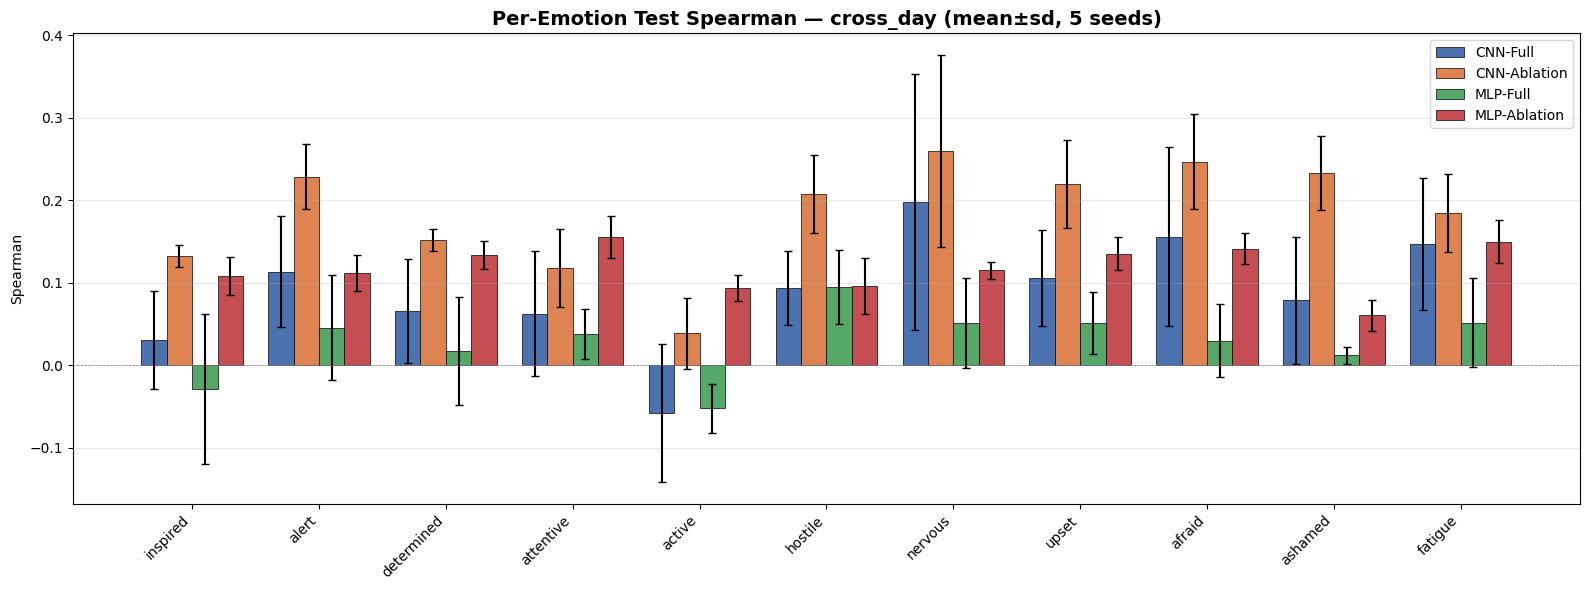

Saved: per_emotion_spearman_cross_day.png


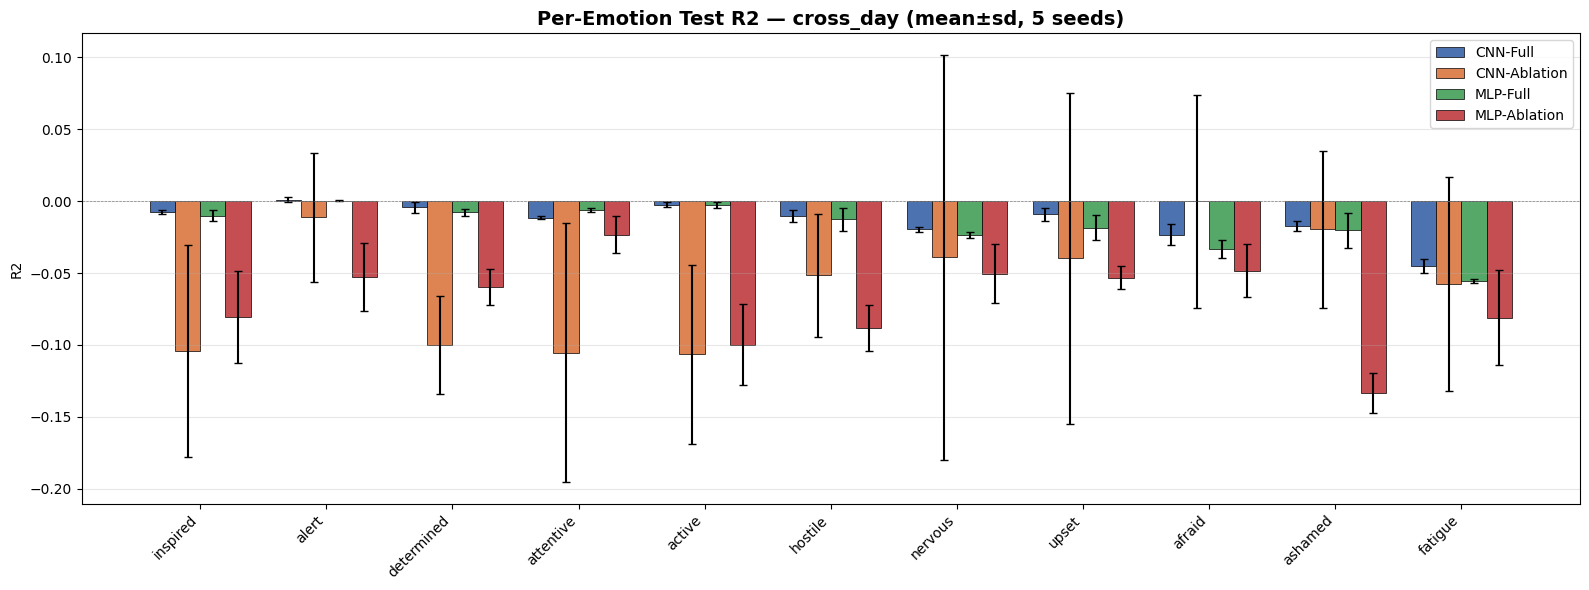

Saved: per_emotion_r2_cross_day.png


In [8]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'DejaVu Sans'
import numpy as np

exp_names = list(EXPERIMENTS.keys())
colors = ['#4C72B0', '#DD8452', '#55A868', '#C44E52']

per_emo_metrics = [('Pearson', 'Test Pearson'), ('Spearman', 'Test Spearman'), ('R2', 'Test R2')]

for metric_name, _ in per_emo_metrics:
    fig, ax = plt.subplots(figsize=(16, 6))
    n_emotions = len(EMOTIONS)
    n_exp = len(exp_names)
    bar_width = 0.8 / n_exp
    x = np.arange(n_emotions)

    for i, exp_name in enumerate(exp_names):
        means, stds = [], []
        for emo in EMOTIONS:
            vals = agg_values(all_data, exp_name, None, per_emotion=emo, metric=metric_name)
            means.append(np.mean(vals))
            stds.append(np.std(vals, ddof=0))
        offset = (i - n_exp / 2 + 0.5) * bar_width
        bars = ax.bar(x + offset, means, bar_width, yerr=stds, capsize=3,
                      label=exp_name, color=colors[i], edgecolor='black', linewidth=0.5)

    ax.set_xticks(x)
    ax.set_xticklabels(EMOTIONS, rotation=45, ha='right', fontsize=10)
    ax.set_ylabel(metric_name)
    ax.set_title(f'Per-Emotion Test {metric_name} \u2014 {split_mode} (mean\u00b1sd, 5 seeds)',
                 fontsize=14, fontweight='bold')
    ax.axhline(y=0, color='gray', linestyle='--', linewidth=0.5)
    ax.legend(fontsize=10)
    ax.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.savefig(f'/root/zjm/cadt_test_code/per_emotion_{metric_name.lower()}_{split_mode}.png',
                dpi=150, bbox_inches='tight')
    plt.show()
    print(f'Saved: per_emotion_{metric_name.lower()}_{split_mode}.png')


---
# cross_subject

## 1. 总体指标对比

In [9]:
split_mode = 'cross_subject'
all_data = all_data_by_split[split_mode]

rows = []
for metric_key, display_name in OVERALL_METRICS:
    row = {'Metric': display_name}
    for exp_name in EXPERIMENTS:
        vals = agg_values(all_data, exp_name, metric_key)
        row[exp_name] = fmt_ms(vals)
    rows.append(row)

df_overall = pd.DataFrame(rows)
df_overall.style.set_caption(f'Overall Metrics — {split_mode} (mean±sd)').set_table_styles([
    {'selector': 'caption', 'props': [('font-size', '16px'), ('font-weight', 'bold')]},
    {'selector': 'th', 'props': [('text-align', 'center')]},
    {'selector': 'td', 'props': [('text-align', 'center')]},
])

,Metric,CNN-Full,CNN-Ablation,MLP-Full,MLP-Ablation
0,Test MSE,0.7118±0.0223,0.8170±0.0844,0.7091±0.0082,0.7647±0.0362
1,Test MAE,0.6965±0.0105,0.7126±0.0297,0.6982±0.0047,0.7049±0.0176
2,Test RMSE,0.8436±0.0132,0.9027±0.0467,0.8421±0.0049,0.8742±0.0208
3,Test R2,0.0926±0.0285,-0.0415±0.1076,0.0961±0.0104,0.0253±0.0462
4,Test Avg R2,-0.1979±0.0379,-0.3618±0.1429,-0.1953±0.0144,-0.2868±0.0615
5,Test Pearson,-0.0193±0.0233,0.0252±0.0203,0.0014±0.0081,-0.0082±0.0082
6,Test Spearman,-0.0419±0.0500,0.0351±0.0324,0.0001±0.0080,-0.0097±0.0058
7,Val MSE,0.9747±0.0079,1.0289±0.0302,0.9737±0.0028,1.0778±0.0093
8,Val MAE,0.7807±0.0013,0.7979±0.0072,0.7818±0.0010,0.8037±0.0051
9,Val RMSE,0.9872±0.0040,1.0142±0.0149,0.9868±0.0014,1.0381±0.0045


## 2. Per-Emotion Test 指标对比

In [10]:
for metric in PER_EMOTION_METRICS:
    rows = []
    for emo in EMOTIONS + ['Average']:
        row = {'Emotion': emo}
        for exp_name in EXPERIMENTS:
            if emo == 'Average':
                vals = agg_values(all_data, exp_name, overall_key_map[metric])
            else:
                vals = agg_values(all_data, exp_name, None, per_emotion=emo, metric=metric)
            row[exp_name] = fmt_ms(vals)
        rows.append(row)

    df_emo = pd.DataFrame(rows).set_index('Emotion')
    display(df_emo.style
            .set_caption(f'Per-Emotion Test {metric} — {split_mode} (mean±sd)')
            .set_table_styles([
                {'selector': 'caption', 'props': [('font-size', '14px'), ('font-weight', 'bold')]},
                {'selector': 'th', 'props': [('text-align', 'center')]},
                {'selector': 'td', 'props': [('text-align', 'center')]},
            ])
            .set_properties(**{'background-color': '#f9f9f9'}, subset=pd.IndexSlice['Average', :]))

,CNN-Full,CNN-Ablation,MLP-Full,MLP-Ablation
Emotion,,,,
inspired,0.9360±0.0595,1.0439±0.1463,0.9297±0.0395,1.0041±0.0821
alert,0.5354±0.0216,0.6491±0.1546,0.5385±0.0113,0.5932±0.0309
determined,0.8588±0.0533,1.0420±0.1074,0.8519±0.0258,0.8406±0.0601
attentive,1.2584±0.0522,1.5166±0.1729,1.2434±0.0089,1.3684±0.0829
active,0.9309±0.0353,1.1597±0.1915,0.9205±0.0162,0.9908±0.0847
hostile,0.3246±0.0080,0.3403±0.0289,0.3261±0.0032,0.3582±0.0193
nervous,0.5621±0.0086,0.6313±0.0836,0.5682±0.0137,0.6139±0.0385
upset,0.9353±0.0065,1.0023±0.0676,0.9308±0.0011,1.0071±0.0297
afraid,0.3430±0.0113,0.3695±0.0555,0.3450±0.0047,0.3796±0.0352


,CNN-Full,CNN-Ablation,MLP-Full,MLP-Ablation
Emotion,,,,
inspired,0.8514±0.0328,0.8782±0.0591,0.8495±0.0224,0.8691±0.0341
alert,0.6749±0.0129,0.6907±0.0396,0.6775±0.0068,0.6824±0.0136
determined,0.8126±0.0310,0.8851±0.0512,0.8120±0.0159,0.8007±0.0298
attentive,0.8944±0.0028,0.9627±0.0355,0.8932±0.0019,0.9627±0.0253
active,0.8209±0.0071,0.8540±0.0285,0.8193±0.0035,0.8259±0.0252
hostile,0.4540±0.0166,0.4360±0.0531,0.4592±0.0067,0.4335±0.0222
nervous,0.6600±0.0077,0.6551±0.0291,0.6661±0.0120,0.6511±0.0265
upset,0.8109±0.0022,0.8121±0.0046,0.8081±0.0012,0.8280±0.0139
afraid,0.5366±0.0130,0.5196±0.0439,0.5405±0.0048,0.5212±0.0262


,CNN-Full,CNN-Ablation,MLP-Full,MLP-Ablation
Emotion,,,,
inspired,-0.5695±0.0998,-0.7505±0.2453,-0.5590±0.0662,-0.6838±0.1377
alert,-0.1963±0.0483,-0.4502±0.3454,-0.2032±0.0252,-0.3254±0.0690
determined,-0.7440±0.1081,-1.1161±0.2181,-0.7300±0.0523,-0.7071±0.1221
attentive,-0.1241±0.0466,-0.3547±0.1544,-0.1107±0.0079,-0.2224±0.0741
active,-0.1310±0.0429,-0.4091±0.2327,-0.1185±0.0196,-0.2038±0.1030
hostile,-0.0774±0.0267,-0.1296±0.0960,-0.0823±0.0108,-0.1889±0.0640
nervous,-0.1026±0.0168,-0.2384±0.1641,-0.1145±0.0270,-0.2042±0.0755
upset,-0.0047±0.0070,-0.0767±0.0726,0.0002±0.0012,-0.0819±0.0319
afraid,-0.2157±0.0401,-0.3094±0.1969,-0.2229±0.0166,-0.3455±0.1249


,CNN-Full,CNN-Ablation,MLP-Full,MLP-Ablation
Emotion,,,,
inspired,-0.0410±0.0419,0.0792±0.0495,-0.0433±0.0405,-0.0169±0.0163
alert,-0.0606±0.0604,-0.0113±0.0857,0.0317±0.0217,-0.0028±0.0210
determined,-0.0515±0.0774,0.0085±0.0817,0.0278±0.0215,0.0256±0.0166
attentive,0.0207±0.0161,-0.0327±0.0206,0.0044±0.0207,-0.0091±0.0157
active,-0.0054±0.0449,-0.0898±0.0565,-0.0696±0.0225,-0.0312±0.0426
hostile,-0.0159±0.0336,0.0407±0.0357,-0.0049±0.0318,-0.0265±0.0240
nervous,-0.0276±0.0235,0.0479±0.0478,0.0274±0.0195,-0.0185±0.0202
upset,-0.0031±0.0601,0.0094±0.0375,0.0205±0.0465,-0.0045±0.0305
afraid,-0.0347±0.0451,0.0613±0.0475,0.0128±0.0099,-0.0101±0.0073


,CNN-Full,CNN-Ablation,MLP-Full,MLP-Ablation
Emotion,,,,
inspired,-0.0545±0.0768,0.1460±0.1087,-0.0337±0.0467,-0.0207±0.0116
alert,-0.1858±0.1001,-0.1194±0.1163,0.0193±0.0226,-0.0092±0.0173
determined,-0.0678±0.2089,-0.0001±0.1352,0.0239±0.0228,0.0218±0.0144
attentive,0.0552±0.0810,-0.0118±0.0462,-0.0024±0.0240,-0.0106±0.0176
active,0.0108±0.1567,-0.0403±0.1132,-0.0656±0.0200,-0.0341±0.0438
hostile,-0.0518±0.1666,0.0812±0.1283,-0.0039±0.0198,-0.0295±0.0278
nervous,-0.1426±0.0522,0.0732±0.0958,0.0311±0.0209,-0.0158±0.0117
upset,0.0605±0.0509,-0.0071±0.0406,0.0229±0.0473,0.0042±0.0243
afraid,-0.0962±0.1346,0.1225±0.0541,0.0041±0.0063,-0.0117±0.0078


## 3. 可视化对比

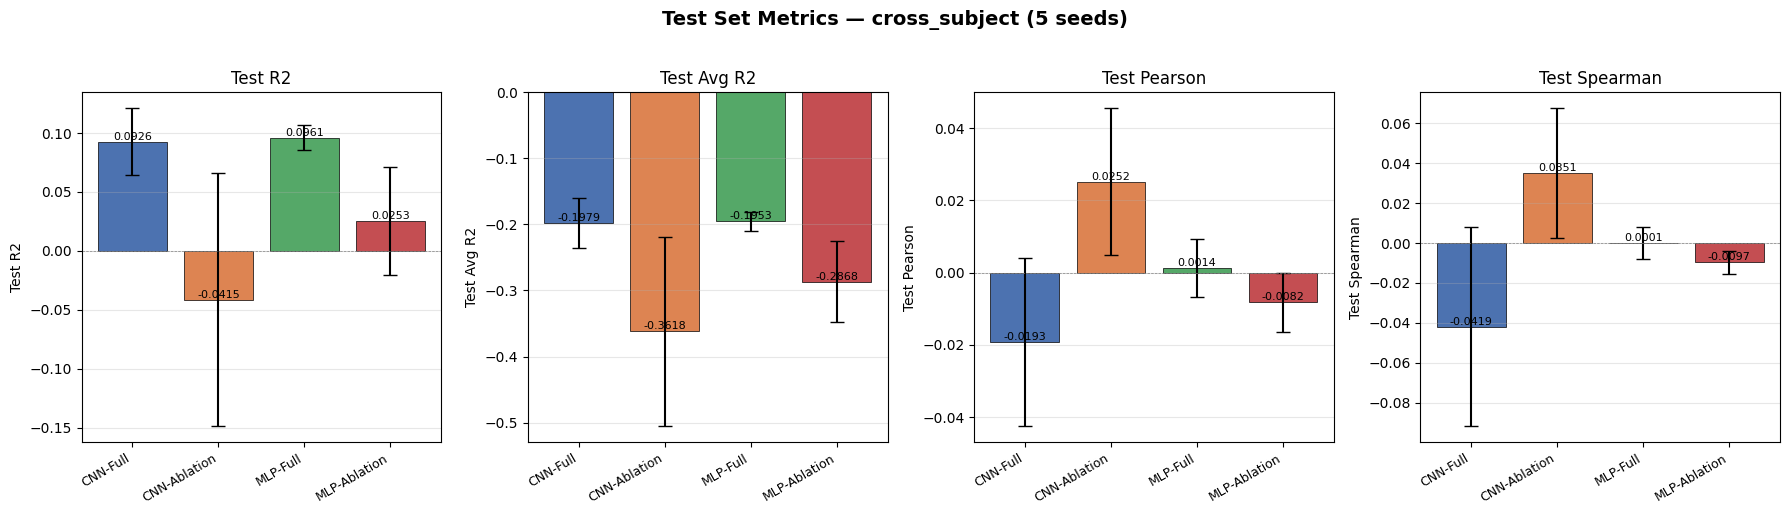

Saved: /root/zjm/cadt_test_code/ablation_comparison_bar_cross_subject.png


In [11]:
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

for ax, metric_key, label in zip(axes, plot_metrics, plot_labels):
    means, stds = [], []
    for exp_name in exp_names:
        vals = agg_values(all_data, exp_name, metric_key)
        means.append(np.mean(vals))
        stds.append(np.std(vals, ddof=0))

    bars = ax.bar(range(len(exp_names)), means, yerr=stds, capsize=5,
                  color=colors, edgecolor='black', linewidth=0.5)
    ax.set_xticks(range(len(exp_names)))
    ax.set_xticklabels(exp_names, rotation=30, ha='right', fontsize=9)
    ax.set_ylabel(label)
    ax.set_title(label, fontsize=12)
    ax.axhline(y=0, color='gray', linestyle='--', linewidth=0.5)
    ax.grid(axis='y', alpha=0.3)
    for bar, m in zip(bars, means):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height(),
                f'{m:.4f}', ha='center', va='bottom', fontsize=8)

plt.suptitle(f'Test Set Metrics — {split_mode} (5 seeds)',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(f'/root/zjm/cadt_test_code/ablation_comparison_bar_{split_mode}.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved: /root/zjm/cadt_test_code/ablation_comparison_bar_{split_mode}.png')

## 4. Per-Emotion Pearson 雷达图

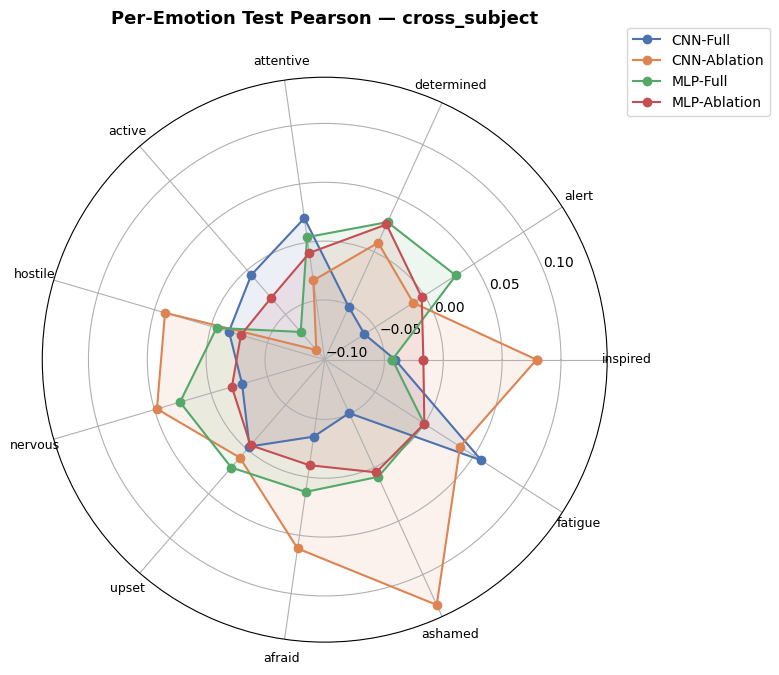

Saved: /root/zjm/cadt_test_code/ablation_radar_pearson_cross_subject.png


In [12]:
fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))

angles = np.linspace(0, 2 * np.pi, len(EMOTIONS), endpoint=False).tolist()
angles += angles[:1]

for exp_name, color in zip(exp_names, colors):
    means = []
    for emo in EMOTIONS:
        vals = agg_values(all_data, exp_name, None, per_emotion=emo, metric='Pearson')
        means.append(np.mean(vals))
    means += means[:1]
    ax.plot(angles, means, 'o-', linewidth=1.5, label=exp_name, color=color)
    ax.fill(angles, means, alpha=0.1, color=color)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(EMOTIONS, fontsize=9)
ax.set_title(f'Per-Emotion Test Pearson — {split_mode}', fontsize=13, fontweight='bold', y=1.08)
ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))
ax.grid(True)
plt.tight_layout()
plt.savefig(f'/root/zjm/cadt_test_code/ablation_radar_pearson_{split_mode}.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved: /root/zjm/cadt_test_code/ablation_radar_pearson_{split_mode}.png')

### Per-Emotion \u5206\u7ec4\u67f1\u72b6\u56fe (Pearson / Spearman / R2)\n
\u6bcf\u4e2a\u60c5\u7eea\u5c55\u793a 4 \u7ec4\u5b9e\u9a8c\u7684 mean\u00b1sd\uff085 seeds\uff09

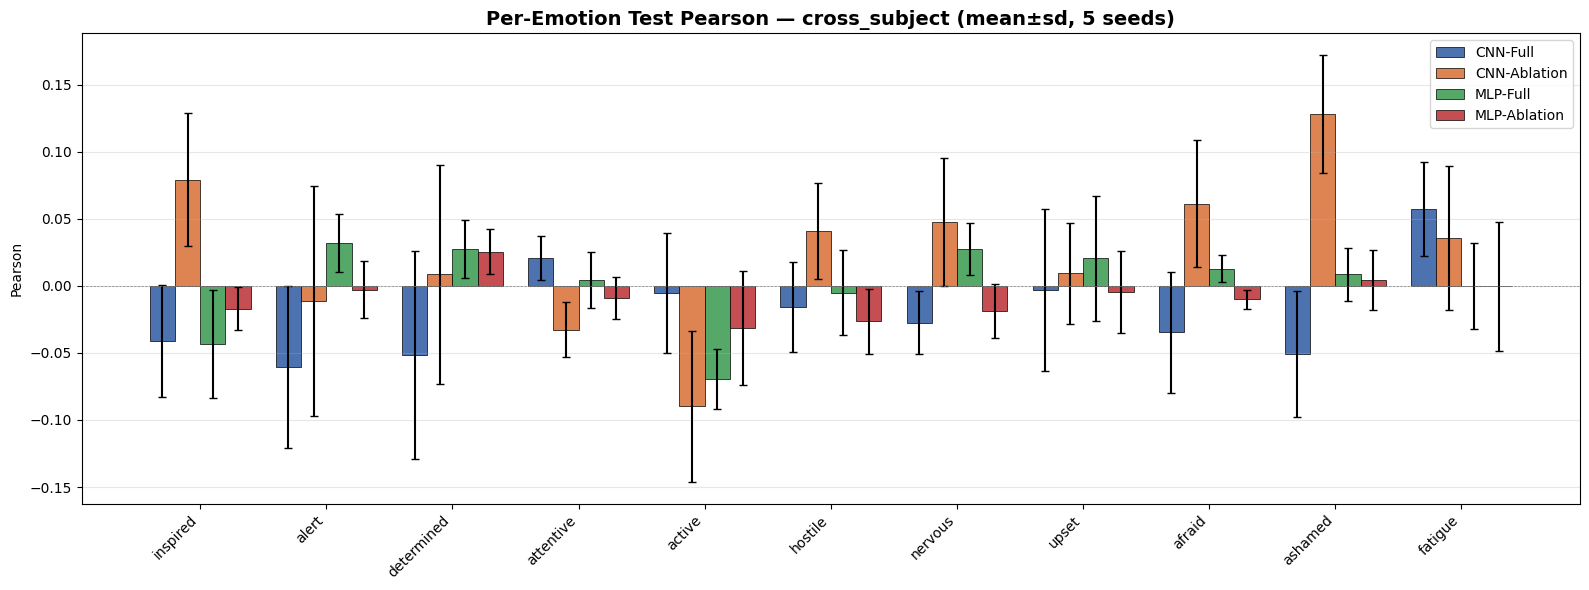

Saved: per_emotion_pearson_cross_subject.png


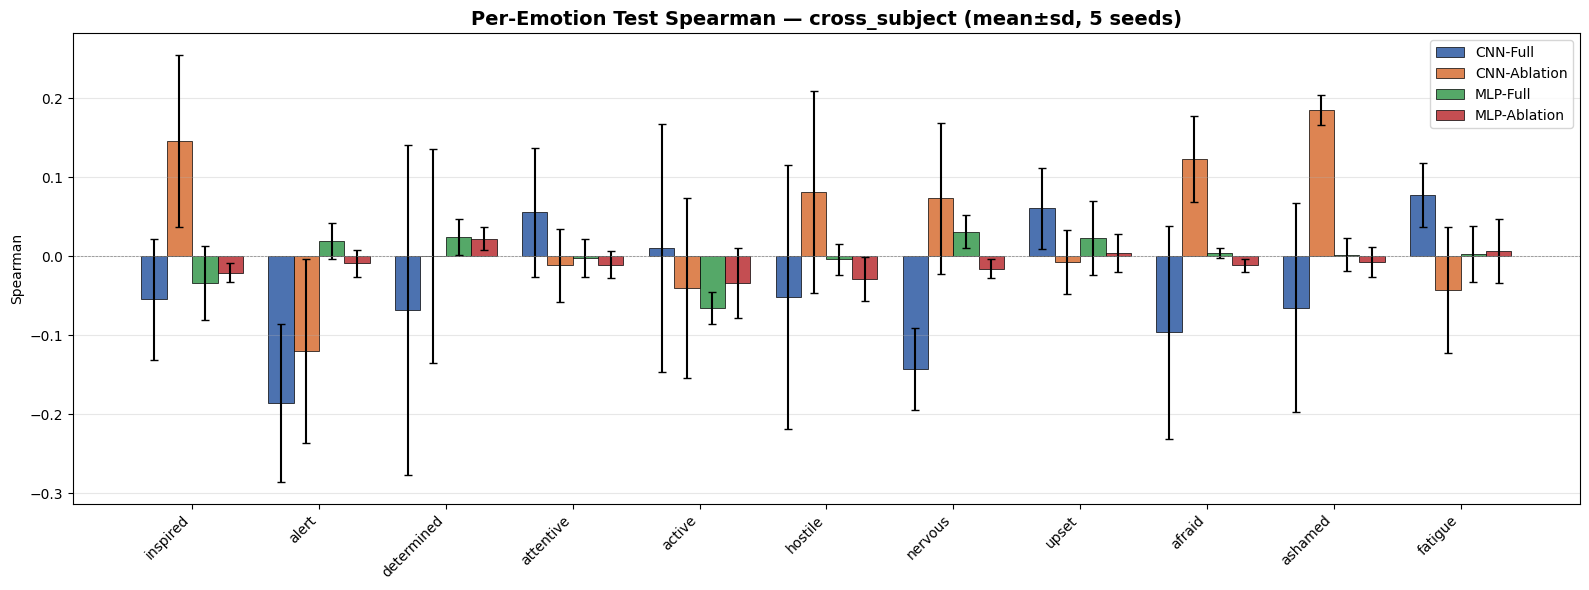

Saved: per_emotion_spearman_cross_subject.png


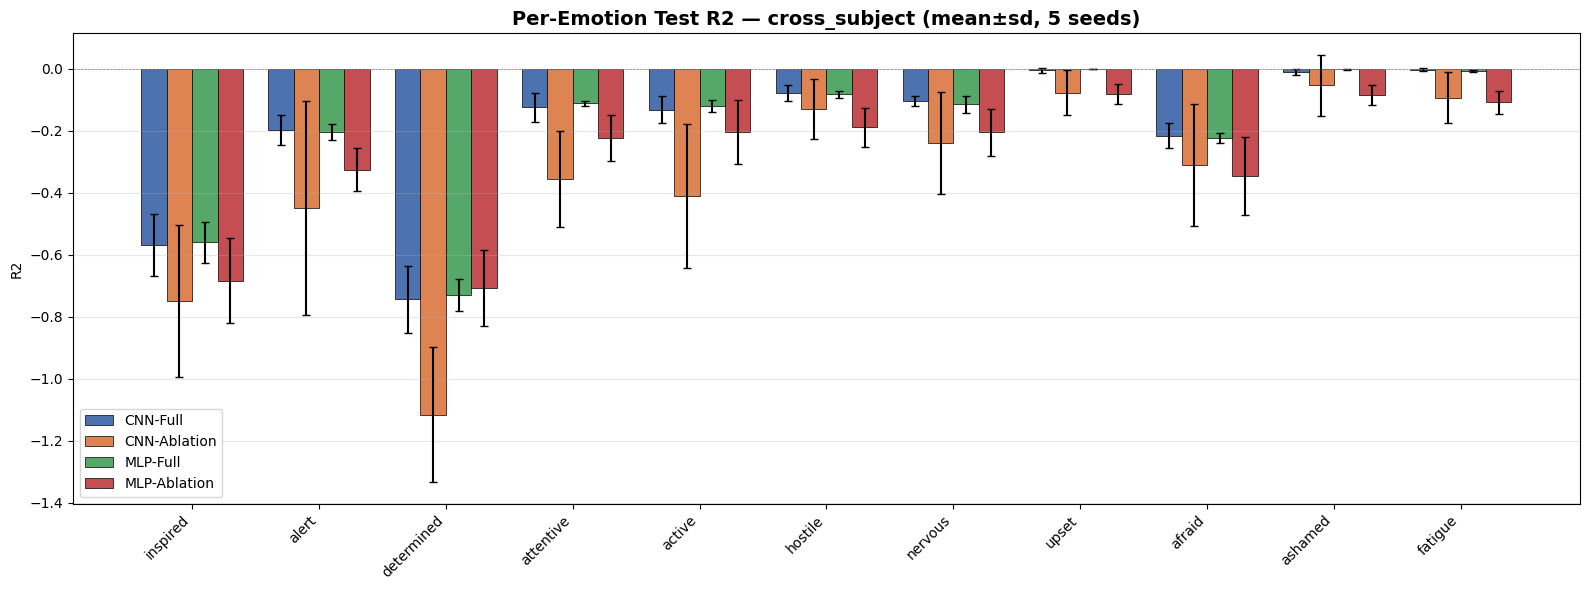

Saved: per_emotion_r2_cross_subject.png


In [13]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'DejaVu Sans'
import numpy as np

exp_names = list(EXPERIMENTS.keys())
colors = ['#4C72B0', '#DD8452', '#55A868', '#C44E52']

per_emo_metrics = [('Pearson', 'Test Pearson'), ('Spearman', 'Test Spearman'), ('R2', 'Test R2')]

for metric_name, _ in per_emo_metrics:
    fig, ax = plt.subplots(figsize=(16, 6))
    n_emotions = len(EMOTIONS)
    n_exp = len(exp_names)
    bar_width = 0.8 / n_exp
    x = np.arange(n_emotions)

    for i, exp_name in enumerate(exp_names):
        means, stds = [], []
        for emo in EMOTIONS:
            vals = agg_values(all_data, exp_name, None, per_emotion=emo, metric=metric_name)
            means.append(np.mean(vals))
            stds.append(np.std(vals, ddof=0))
        offset = (i - n_exp / 2 + 0.5) * bar_width
        bars = ax.bar(x + offset, means, bar_width, yerr=stds, capsize=3,
                      label=exp_name, color=colors[i], edgecolor='black', linewidth=0.5)

    ax.set_xticks(x)
    ax.set_xticklabels(EMOTIONS, rotation=45, ha='right', fontsize=10)
    ax.set_ylabel(metric_name)
    ax.set_title(f'Per-Emotion Test {metric_name} \u2014 {split_mode} (mean\u00b1sd, 5 seeds)',
                 fontsize=14, fontweight='bold')
    ax.axhline(y=0, color='gray', linestyle='--', linewidth=0.5)
    ax.legend(fontsize=10)
    ax.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.savefig(f'/root/zjm/cadt_test_code/per_emotion_{metric_name.lower()}_{split_mode}.png',
                dpi=150, bbox_inches='tight')
    plt.show()
    print(f'Saved: per_emotion_{metric_name.lower()}_{split_mode}.png')


---
# 5. 两种 split mode 并排对比

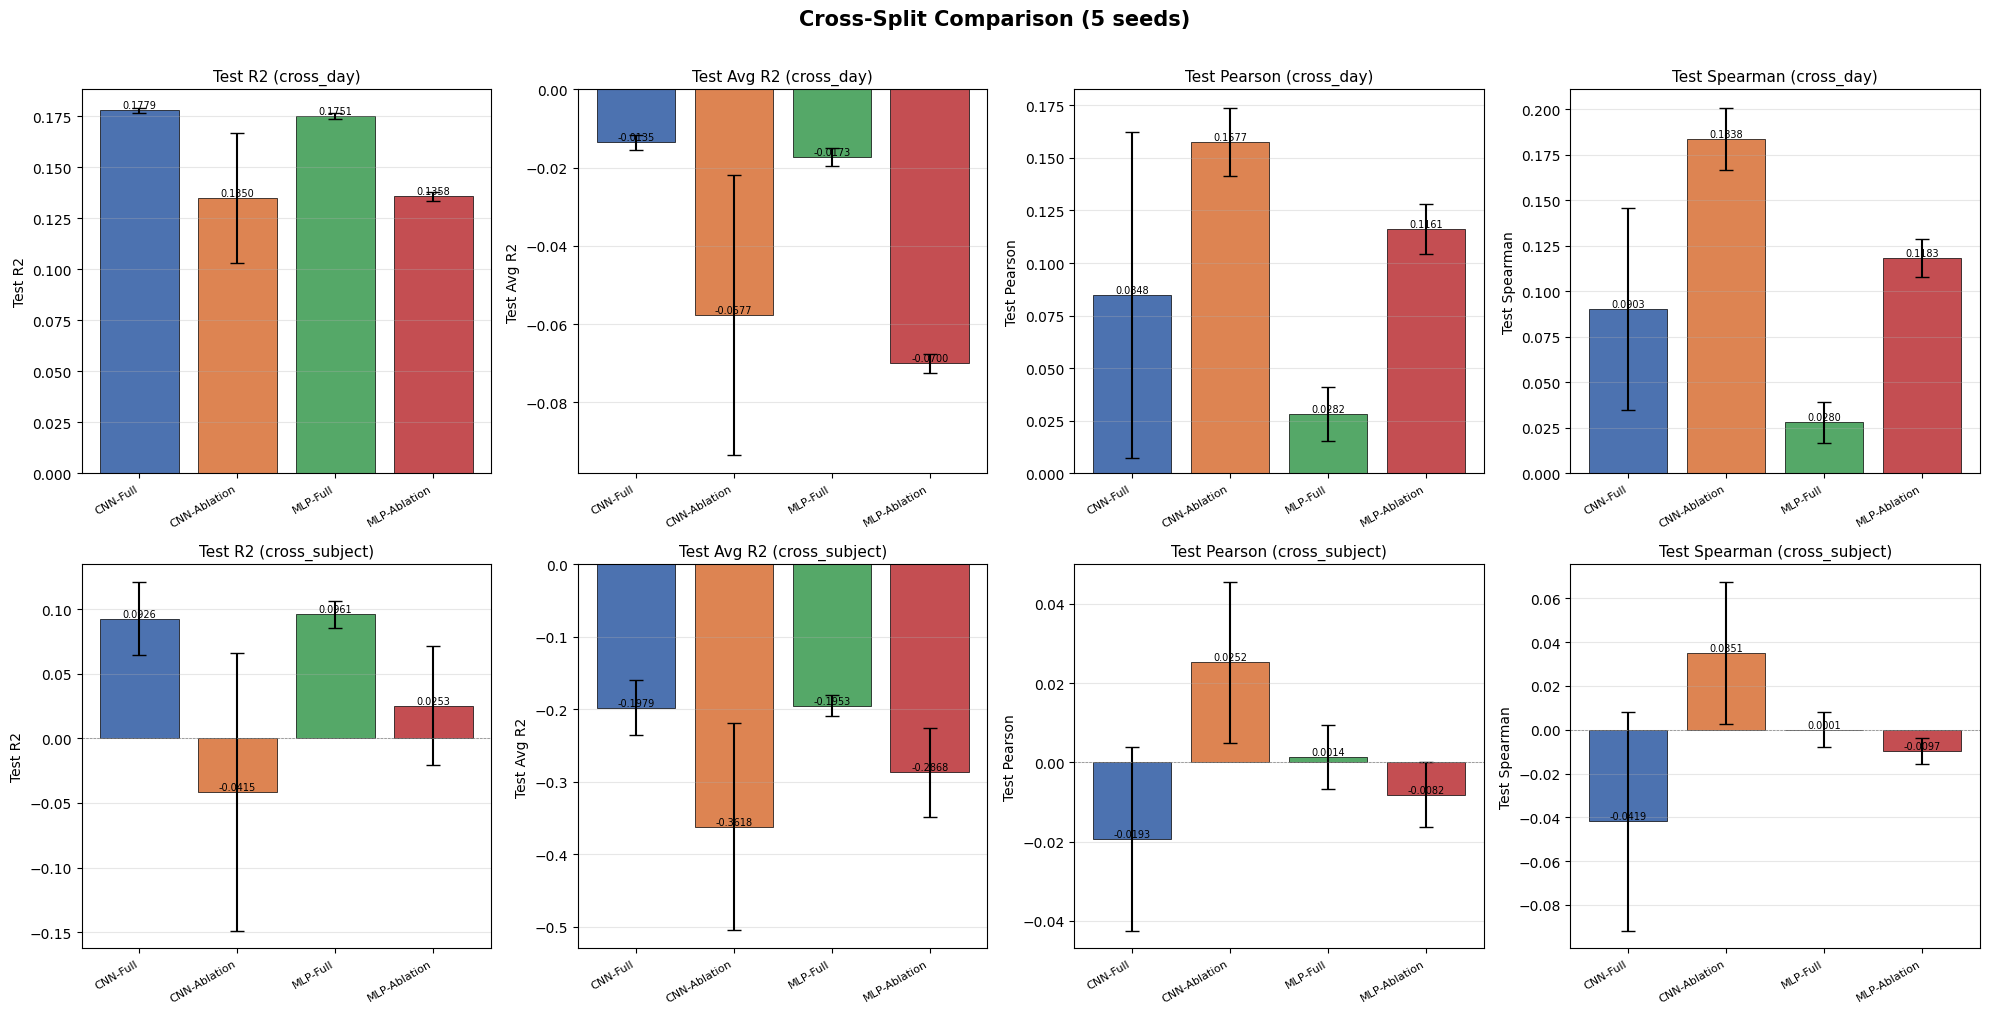

Saved: /root/zjm/cadt_test_code/ablation_comparison_cross_split.png


In [14]:
fig, axes = plt.subplots(2, 4, figsize=(20, 10))

for row_idx, split_mode in enumerate(SPLIT_MODES):
    all_data = all_data_by_split[split_mode]
    for col_idx, (metric_key, label) in enumerate(zip(plot_metrics, plot_labels)):
        ax = axes[row_idx][col_idx]
        means, stds = [], []
        for exp_name in exp_names:
            vals = agg_values(all_data, exp_name, metric_key)
            means.append(np.mean(vals))
            stds.append(np.std(vals, ddof=0))

        bars = ax.bar(range(len(exp_names)), means, yerr=stds, capsize=5,
                      color=colors, edgecolor='black', linewidth=0.5)
        ax.set_xticks(range(len(exp_names)))
        ax.set_xticklabels(exp_names, rotation=30, ha='right', fontsize=8)
        ax.set_ylabel(label)
        ax.set_title(f'{label} ({split_mode})', fontsize=11)
        ax.axhline(y=0, color='gray', linestyle='--', linewidth=0.5)
        ax.grid(axis='y', alpha=0.3)
        for bar, m in zip(bars, means):
            ax.text(bar.get_x() + bar.get_width()/2, bar.get_height(),
                    f'{m:.4f}', ha='center', va='bottom', fontsize=7)

plt.suptitle('Cross-Split Comparison (5 seeds)', fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('/root/zjm/cadt_test_code/ablation_comparison_cross_split.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: /root/zjm/cadt_test_code/ablation_comparison_cross_split.png')

## 6. 导出 CSV

In [15]:
output_dir = '/root/zjm/cadt_test_code'

for split_mode in SPLIT_MODES:
    all_data = all_data_by_split[split_mode]

    # overall
    rows = []
    for metric_key, display_name in OVERALL_METRICS:
        row = {'Metric': display_name}
        for exp_name in EXPERIMENTS:
            vals = agg_values(all_data, exp_name, metric_key)
            row[exp_name] = fmt_ms(vals)
        rows.append(row)
    pd.DataFrame(rows).to_csv(os.path.join(output_dir, f'compare_ablation_overall_{split_mode}.csv'), index=False)
    print(f'Saved: compare_ablation_overall_{split_mode}.csv')

    # per-emotion
    for metric in PER_EMOTION_METRICS:
        rows = []
        for emo in EMOTIONS + ['Average']:
            row = {'Emotion': emo}
            for exp_name in EXPERIMENTS:
                if emo == 'Average':
                    vals = agg_values(all_data, exp_name, overall_key_map[metric])
                else:
                    vals = agg_values(all_data, exp_name, None, per_emotion=emo, metric=metric)
                row[exp_name] = fmt_ms(vals)
            rows.append(row)
        pd.DataFrame(rows).to_csv(os.path.join(output_dir, f'compare_ablation_test_{metric}_{split_mode}.csv'), index=False)
        print(f'Saved: compare_ablation_test_{metric}_{split_mode}.csv')

print('Done!')

Saved: compare_ablation_overall_cross_day.csv
Saved: compare_ablation_test_MSE_cross_day.csv
Saved: compare_ablation_test_MAE_cross_day.csv
Saved: compare_ablation_test_R2_cross_day.csv
Saved: compare_ablation_test_Pearson_cross_day.csv
Saved: compare_ablation_test_Spearman_cross_day.csv
Saved: compare_ablation_overall_cross_subject.csv
Saved: compare_ablation_test_MSE_cross_subject.csv
Saved: compare_ablation_test_MAE_cross_subject.csv
Saved: compare_ablation_test_R2_cross_subject.csv
Saved: compare_ablation_test_Pearson_cross_subject.csv
Saved: compare_ablation_test_Spearman_cross_subject.csv
Done!
